# 04 - Train and select the serving model

Run notebook 03 first (or `uv run pm-train`). All cycles of an engine stay in the same cross-validation fold. The serving champion is chosen by mean training-validation RMSE; held-out test scores are reporting-only.

The default fits linear regression with its scaler, XGBoost, and LightGBM. Set `TRAIN_LSTM = True` only after installing `uv sync --locked --extra notebooks --extra deep-learning`. LSTM remains an optional experiment, outside the classical champion selection.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "predictive_maintenance").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project root or its notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PM_PROJECT_ROOT", str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display
from loguru import logger
from predictive_maintenance.config import (
    EXTERNAL_DATA_DIR, RAW_DATA_DIR, INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR,
    RUL_CAP, TREND_WINDOW, SETTINGS,
)

logger.remove()
logger.add(sys.stderr, level="WARNING")
pd.set_option("display.max_columns", 40)
print(f"Project: {ROOT.name} | Python: {sys.version.split()[0]}")


Project: Predictive-Maintenance-for-Sensor-Data | Python: 3.13.9


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
import json
import shutil
from predictive_maintenance.models.train import train_pipeline

TRAIN_LSTM = False
N_SPLITS = SETTINGS.get("n_splits", 5)
required = [PROCESSED_DATA_DIR / f"{split}_{kind}.csv"
            for split in ("train", "test") for kind in ("features", "labels")]
required.append(INTERIM_DATA_DIR / "constant_columns.json")
if any(not path.exists() for path in required):
    raise FileNotFoundError("Run notebooks 02 and 03, or `uv run pm-train`, before training.")

train_pipeline(
    features_path=PROCESSED_DATA_DIR / "train_features.csv",
    labels_path=PROCESSED_DATA_DIR / "train_labels.csv",
    test_features_path=PROCESSED_DATA_DIR / "test_features.csv",
    test_labels_path=PROCESSED_DATA_DIR / "test_labels.csv",
    n_splits=N_SPLITS, train_lstm=TRAIN_LSTM,
)
shutil.copy(INTERIM_DATA_DIR / "constant_columns.json", MODELS_DIR / "constant_columns.json")
comparison = pd.read_csv(RESULTS_DIR / "model_comparison.csv")
display(comparison.sort_values("RMSE_mean"))


,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,LightGBM,12.912403,1.198666,17.825632,1.524688
2,XGBoost,13.029350,1.230391,17.942778,1.547701
1,LinearRegression,16.967198,1.062759,20.920921,1.053402


## Cross-validation uncertainty

These errors use all validation cycles. Error bars show standard deviation across engine folds, not test uncertainty.


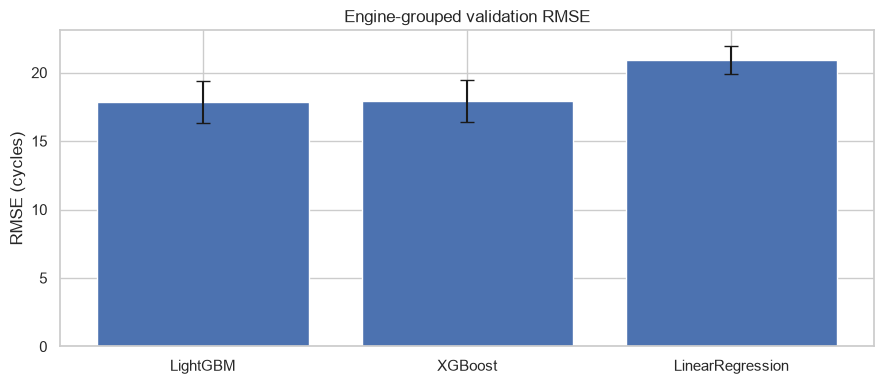

In [4]:
ordered = comparison.sort_values("RMSE_mean")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(ordered.model, ordered.RMSE_mean, yerr=ordered.RMSE_std, capsize=5)
ax.set(title="Engine-grouped validation RMSE", ylabel="RMSE (cycles)")
plt.tight_layout()
plt.show()


## Inspect the selected artifact and reporting-only test scores


In [5]:
manifest = json.loads((MODELS_DIR / "best_model.json").read_text())
assert manifest["selection_metric"] == "groupkfold_RMSE"
assert manifest["model_name"] == comparison.loc[comparison.RMSE_mean.idxmin(), "model"]
display(pd.Series(manifest, name="selected_model").to_frame())
display(pd.read_csv(RESULTS_DIR / "test_evaluation.csv"))


,selected_model
model_name,LightGBM
test_RMSE,16.37704
test_MAE,11.826881
files,"{'model': 'lightgbm.pkl', 'features': 'lightgb..."
selection_metric,groupkfold_RMSE
validation_RMSE,17.825632
preprocessing,"{'trend_window': 10, 'rul_cap': 125}"


,model,MAE,RMSE,n_engines
0,LightGBM,11.826881,16.377040,100
1,XGBoost,12.304318,16.527736,100
2,LinearRegression,16.021368,20.254767,100


**Next:** `05_model_evaluation.ipynb`. Model files, feature lists, and constant-column metadata must remain together for API inference.
